# Swachh Bharat Mission: Computational Text Analysis of Stakeholder Framing

Code for the paper *A Computational Text Analysis of Stakeholder Framing in the Swachh Bharat Mission* (Aahwaan Khullar, 2026).

The notebook analyses a 55-document corpus of government, academic, journalistic, and civil-society writing on the Swachh Bharat Mission (SBM) and asks whether sentiment and themes differ by **source type** and by **stakeholder group**.

**Pipeline:** load corpus → clean and tokenize → remove stopwords → stem and lemmatize → word frequency → VADER sentiment → sentiment by source type (with a Mann–Whitney U test) → sentiment by stakeholder group → LDA topic modeling → export.

**Note on the corpus:** each document is represented by a short summary of the source, not its full text (see the paper, Section 3.2). Results are descriptive and preliminary.

## 1. Setup
In Google Colab, run the cell below once. Locally, `pip install -r requirements.txt` and run the NLTK downloads.

In [ ]:
!pip install vaderSentiment -q

import nltk
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
                 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

## 2. Load the corpus

In [1]:
import pandas as pd

df = pd.read_csv("data/sbm_corpus.csv")
print("Corpus shape:", df.shape)
print(df['source_type'].value_counts().to_string())

Corpus shape: (55, 8)
source_type
academic_paper              17
news_report                 11
government_press_release     7
policy_briefing              6
investigative_journalism     6
ngo_report                   4
opinion_analysis             4


## 3. Cleaning and tokenization
Lower-casing, removing URLs and digits, then NLTK's `word_tokenize`, which separates punctuation and contractions correctly.

In [2]:
import re, string
from nltk.tokenize import word_tokenize

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    return text

df['tokens'] = df['text'].apply(clean_text).apply(word_tokenize)
df['tokens'] = df['tokens'].apply(lambda toks: [t for t in toks if t not in string.punctuation])
print(df.loc[0, 'tokens'][:15])

['broad', 'review', 'of', 'sbm', "'s", 'first', 'decade', 'covering', 'sanitation', 'and', 'municipal', 'waste', 'management', 'alongside', 'urban']


## 4. Stopword removal
NLTK's English stopword list plus corpus-specific terms that appear in nearly every document ("india", "mission", "swachh", "bharat", ...). Tokens shorter than three characters and non-alphabetic fragments such as "n't" are also dropped.

In [3]:
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words('english')) | {
    "india", "indian", "mission", "swachh", "bharat", "sbm",
    "also", "said", "would", "could", "one", "two", "within", "across"}

def remove_stopwords(tokens):
    return [t for t in tokens if t.isalpha() and t not in STOPWORDS and len(t) > 2]

df['tokens_clean'] = df['tokens'].apply(remove_stopwords)
print(df.loc[0, 'tokens_clean'][:15])

['broad', 'review', 'first', 'decade', 'covering', 'sanitation', 'municipal', 'waste', 'management', 'alongside', 'urban', 'population', 'growth', 'reach', 'firm']


## 5. Stemming and lemmatization
Both are computed; POS-aware lemmatization is used for the rest of the analysis because lemmas are real words and easier to check by eye.

In [4]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()

def get_wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'N': wordnet.NOUN, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(w, get_wordnet_pos(t)) for w, t in pos_tag(tokens)]

df['stems'] = df['tokens_clean'].apply(lambda toks: [stemmer.stem(t) for t in toks])
df['lemmas'] = df['tokens_clean'].apply(lemmatize_tokens)
print("Stemmed:   ", df.loc[0, 'stems'][:10])
print("Lemmatized:", df.loc[0, 'lemmas'][:10])

Stemmed:    ['broad', 'review', 'first', 'decad', 'cover', 'sanit', 'municip', 'wast', 'manag', 'alongsid']
Lemmatized: ['broad', 'review', 'first', 'decade', 'cover', 'sanitation', 'municipal', 'waste', 'management', 'alongside']


## 6. Word frequency

toilet         18
sanitation     17
open           13
defecation     13
waste          11
report         11
crore          11
study          10
menstrual      10
rather         9
government     9
state          8
household      8
cover          7
management     7
gap            7
year           7
death          7
campaign       7
policy         7


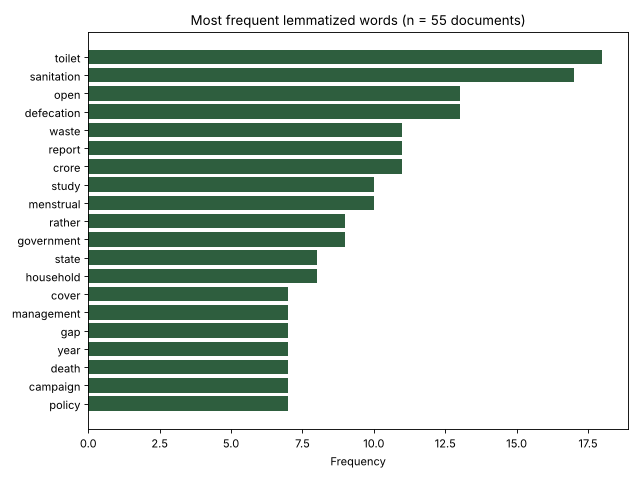

In [5]:
from collections import Counter
import matplotlib.pyplot as plt

freq = Counter(w for row in df['lemmas'] for w in row)
top20 = freq.most_common(20)
for word, count in top20:
    print(f"{word:14s} {count}")

words, counts = zip(*top20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(words[::-1], counts[::-1], color="#2E5E3E")
ax.set_title(f"Most frequent lemmatized words (n = {len(df)} documents)")
ax.set_xlabel("Frequency")
plt.tight_layout(); plt.savefig("figures/fig2_word_frequency.png", dpi=200); plt.show()

## 7. Sentiment analysis (VADER)
VADER (Hutto & Gilbert, 2014) is run on the original text, because it uses capitalization, punctuation, and word order. Each document gets a compound score from -1 to +1.

In [6]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()
df['sentiment'] = df['text'].apply(lambda t: analyzer.polarity_scores(t)['compound'])

by_type = df.groupby('source_type')['sentiment'].agg(['mean', 'std', 'count']).sort_values('mean')
print(by_type.round(3))

                           mean    std  count
source_type                                  
opinion_analysis         -0.502  0.367      4
investigative_journalism -0.373  0.516      6
news_report              -0.112  0.482     11
academic_paper           -0.030  0.447     17
policy_briefing           0.072  0.302      6
government_press_release  0.138  0.409      7
ngo_report                0.162  0.554      4


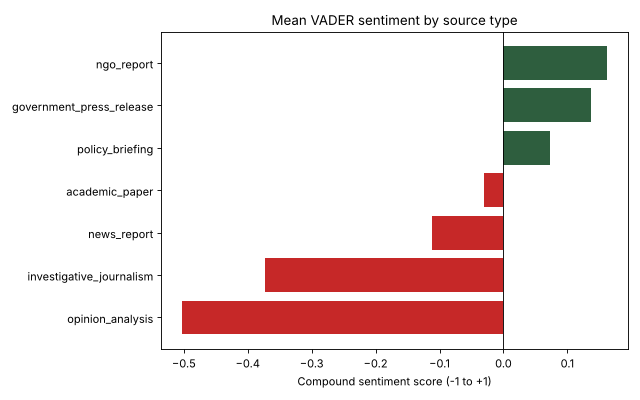

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_type.index, by_type['mean'], color=["#C62828" if v < 0 else "#2E5E3E" for v in by_type['mean']])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Mean VADER sentiment by source type")
ax.set_xlabel("Compound sentiment score (-1 to +1)")
plt.tight_layout(); plt.savefig("figures/fig3_sentiment_by_source_type.png", dpi=200); plt.show()

### Is the institutional–critical difference larger than chance?
Two-sided Mann–Whitney U test comparing the most institutional sources (government press releases, policy briefings) with the most critical (investigative journalism, opinion pieces). It does not assume normally distributed scores, which suits small groups.

In [8]:
from scipy.stats import mannwhitneyu

institutional = df[df['source_type'].isin(['government_press_release', 'policy_briefing'])]['sentiment']
critical = df[df['source_type'].isin(['investigative_journalism', 'opinion_analysis'])]['sentiment']
u, p = mannwhitneyu(institutional, critical, alternative='two-sided')
print(f"Institutional: mean {institutional.mean():+.3f} (n = {len(institutional)})")
print(f"Critical:      mean {critical.mean():+.3f} (n = {len(critical)})")
print(f"Mann-Whitney U = {u:.1f}, p = {p:.4f}")

Institutional: mean +0.107 (n = 13)
Critical:      mean -0.425 (n = 10)
Mann-Whitney U = 107.5, p = 0.0088


## 8. Sentiment by stakeholder group
Documents can carry several stakeholder tags, so each tag is counted separately. Groups with fewer than two documents are excluded. The standard deviation is reported because a near-zero mean can hide strongly positive and strongly negative documents.

                           mean    std  count
stakeholder                                  
marginalized_castes      -0.535  0.404      5
general_public           -0.492  0.531      3
sanitation_workers       -0.263  0.428     10
urban_local_bodies       -0.239  0.468     14
policy_experts           -0.144  0.581      4
students                 -0.007  0.357      6
government               -0.002  0.456     31
marginalized_communities  0.000  0.809      2
rural_households          0.034  0.477     15
women                     0.130  0.385     10
public_health             0.258  0.532      3
citizens                  0.312  0.442      2


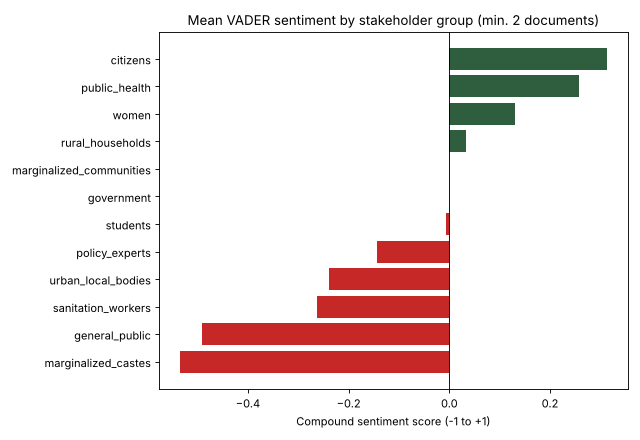

In [9]:
stakeholder_df = df.assign(stakeholder=df['stakeholder_tag'].str.split(';')).explode('stakeholder')
by_stakeholder = stakeholder_df.groupby('stakeholder')['sentiment'].agg(['mean', 'std', 'count'])
by_stakeholder = by_stakeholder[by_stakeholder['count'] >= 2].sort_values('mean')
print(by_stakeholder.round(3))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(by_stakeholder.index, by_stakeholder['mean'],
        color=["#C62828" if v < 0 else "#2E5E3E" for v in by_stakeholder['mean']])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Mean VADER sentiment by stakeholder group (min. 2 documents)")
ax.set_xlabel("Compound sentiment score (-1 to +1)")
plt.tight_layout(); plt.savefig("figures/fig4_sentiment_by_stakeholder.png", dpi=200); plt.show()

### Sanitation workers: the spread behind the average
The same deaths read very differently depending on who reports them.

In [10]:
sw = df[df['stakeholder_tag'].str.contains('sanitation_workers')]
print(sw[['id', 'source_type', 'sentiment', 'title']].sort_values('sentiment').to_string(index=False))

 id              source_type  sentiment                                                                            title
 20 investigative_journalism    -0.9022      India's Sewer Death Crisis: Why Fatalities Don't Count as Manual Scavenging
 17 investigative_journalism    -0.7964            One Death Every Few Days: Sanitation Workers Protest at Jantar Mantar
 16              news_report    -0.7845              India rejects UN official's criticism (manual scavenging and caste)
 19              news_report    -0.2732             52 Sanitation Workers Lost Lives Due to Hazardous Cleaning in a Year
 55              news_report    -0.2263                  Two sanitation workers die cleaning sewage shaft at Noida house
 11 investigative_journalism    -0.1280                             How the Swachh Bharat Mission is heading for failure
 54              news_report     0.0000        288 people died cleaning sewers, septic tanks in last 3 years: Government
  8          policy_briefing    

## 9. Topic modeling (LDA)
Latent Dirichlet Allocation (Blei, Ng & Jordan, 2003) on TF-IDF-weighted lemmas; five topics, fixed random seed for reproducibility.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vectorizer = TfidfVectorizer(max_df=0.85, min_df=2)
tfidf = vectorizer.fit_transform(df['lemmas'].apply(" ".join))
print("TF-IDF matrix shape:", tfidf.shape)

lda = LatentDirichletAllocation(n_components=5, random_state=42, max_iter=20)
doc_topic = lda.fit_transform(tfidf)
terms = vectorizer.get_feature_names_out()
for i, topic in enumerate(lda.components_):
    print(f"Topic {i+1}: {', '.join(terms[j] for j in topic.argsort()[-10:][::-1])}")

df['dominant_topic'] = doc_topic.argmax(axis=1) + 1

TF-IDF matrix shape: (55, 229)
Topic 1: cleanliness, campaign, official, frame, responsibility, piece, waste, infrastructure, cover, crore
Topic 2: sanitation, woman, student, practice, death, note, household, hygiene, parliamentary, menstrual
Topic 3: rural, death, grant, instead, review, scheme, municipal, attention, literature, people
Topic 4: toilet, sanitation, open, defecation, clean, management, ministry, waste, year, report
Topic 5: rather, menstrual, study, guideline, design, problem, toilet, gap, policy, school


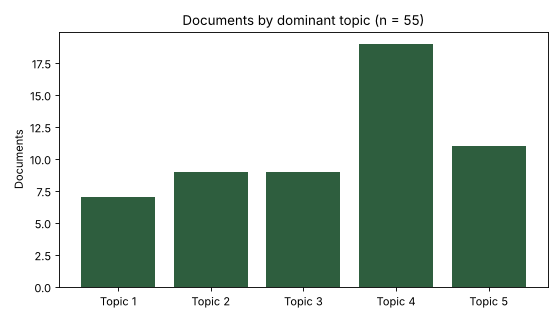

In [12]:
counts = df['dominant_topic'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([f"Topic {i}" for i in counts.index], counts.values, color="#2E5E3E")
ax.set_title("Documents by dominant topic (n = 55)")
ax.set_ylabel("Documents")
plt.tight_layout(); plt.savefig("figures/fig5_topic_distribution.png", dpi=200); plt.show()

## 10. Export results

In [13]:
df[['id', 'title', 'source_type', 'stakeholder_tag', 'sentiment', 'dominant_topic']].to_csv(
    "results/sbm_analysis_results.csv", index=False)
by_type.to_csv("results/sentiment_by_source_type.csv")
by_stakeholder.to_csv("results/sentiment_by_stakeholder.csv")
print("Exported to results/")

Exported to results/


## Limitations
- The corpus text consists of short summaries, not full source documents. An earlier version of these summaries contained the author's own research notes, which VADER scored as part of the text; they were removed and all results re-run (paper, Section 5.2).
- 55 documents is enough for descriptive analysis but modest for inference; several stakeholder groups have only two or three documents.
- English-language sources only.
- Lexicon-based tools such as VADER can misread bureaucratic or statistical prose.
- Stakeholder tags were assigned by a single coder.